In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Plot Parameters
plt.rcParams["font.family"] = "FreeSerif"
plt.rcParams.update({'font.size': 18})
plt.rc('legend', fontsize=16)    # legend fontsize
plt.rcParams['mathtext.fontset'] = 'stix'


# SETUP
data_path = '/home/nfarias/nicole_data/NEI_vs_Rfrac/date_20250310_'

PLOT_HIST = True

# Choose Rfracs to plot
# rfracs = np.array([1.0, 0.84, 0.82,  0.73, 0.68, 0.63, 0.5])
rfracs = np.array([1.0])

1.0 20.01389625111768
Median readout NEI:  17.87


/home/nfarias/.local/lib/python3.10/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/nfarias/.local/lib/python3.10/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)
/home/nfarias/.local/lib/python3.10/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/home/nfarias/.local/lib/python3.10/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/home/nfarias/.local/lib/python3.10/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


Median readout NEI:  17.87


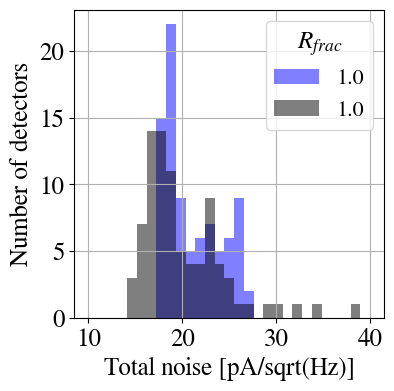

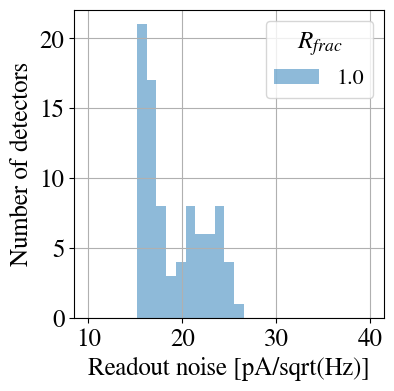

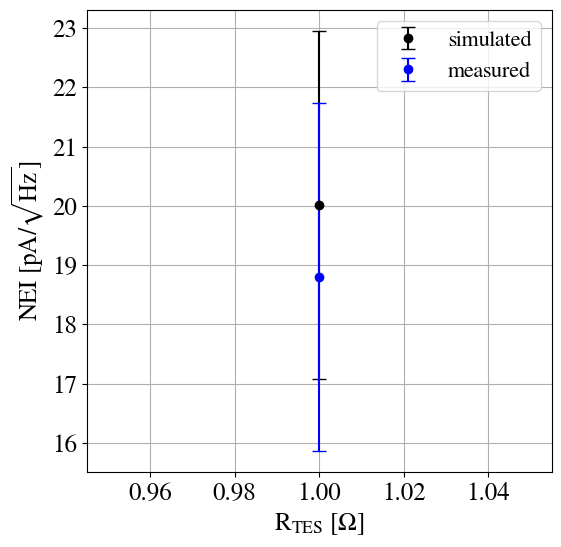

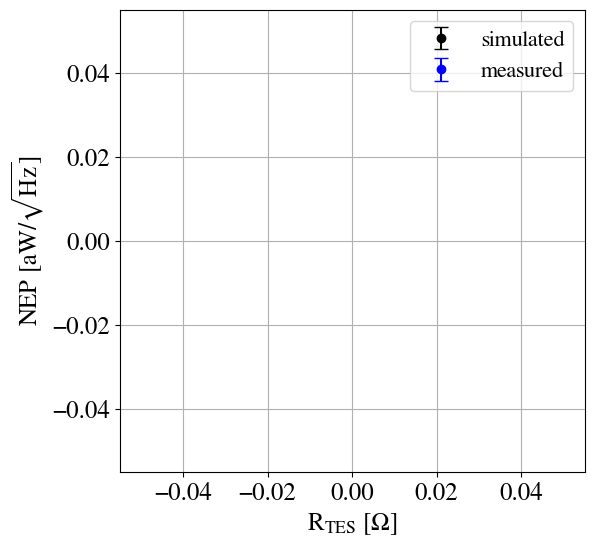

In [2]:
# Initialize arrays to store  NEI data
median_readout_neis = np.zeros(len(rfracs))
std_readout_neis = np.zeros(len(rfracs))
median_total_neis = np.zeros(len(rfracs))
std_total_neis = np.zeros(len(rfracs))
median_measured_neis = np.zeros(len(rfracs))
std_measured_neis = np.zeros(len(rfracs))
# and NEP data
median_readout_neps = np.zeros(len(rfracs))
std_readout_neps = np.zeros(len(rfracs))
median_total_neps = np.zeros(len(rfracs))
std_total_neps = np.zeros(len(rfracs))
median_measured_neps = np.zeros(len(rfracs))
std_measured_neps = np.zeros(len(rfracs))

for r, rfrac in enumerate(rfracs):
    
    # load data generated by readout_noise_vs_rfrac.py (numpy arrays)
    # simulated data
    sim_readout_nei = np.load(f'{data_path}readout_nei_{rfrac}.npy')
    sim_total_nei = np.load(f'{data_path}total_nei_{rfrac}.npy')
    sim_readout_nep = np.load(f'{data_path}readout_nep_{rfrac}.npy')
    sim_total_nep = np.load(f'{data_path}total_nep_{rfrac}.npy')
    # measured data
    measured_total_nep = np.load(f'{data_path}measured_nep_{rfrac}.npy')
    measured_total_nei = np.load(f'{data_path}measured_nei_{rfrac}.npy')
    
    # get medians and standard deviations
    
    # NEIs
    median_readout_neis[r] = np.median(sim_readout_nei)
    std_readout_neis[r] = np.std(sim_readout_nei)
    
    median_total_neis[r] = np.median(sim_total_nei)
    std_total_neis[r] = np.std(sim_total_nei)
    print(rfrac, median_total_neis[r]*1e12)
    
    median_measured_neis[r] = np.median(measured_total_nei)
    std_measured_neis[r] = np.std(measured_total_nei)
    
    # NEPS
    
    median_readout_neps[r] = np.median(sim_readout_nep)
    std_readout_neps[r] = np.std(sim_readout_nep)
    
    median_total_neps[r] = np.median(sim_total_nep)
    std_total_neps[r] = np.std(sim_total_nep)
    
    median_measured_neps[r] = np.median(measured_total_nep)
    std_measured_neps[r] = np.std(measured_total_nep)
    
    # PLOT THINGS
    if PLOT_HIST:
        plt.figure(11, figsize=(4,4))
        bins=np.linspace(10, 40, 30)
        plt.hist(sim_total_nei*1e12 , label=str(round(rfrac, 2)), alpha=0.5, bins=bins, \
            color='blue')
        plt.hist(measured_total_nei*1e12 , label=str(round(rfrac, 2)), alpha=0.5, bins=bins, \
            color='black')
        plt.xlabel("Total noise [pA/sqrt(Hz)]")
        plt.ylabel("Number of detectors")
        # plt.title("Using Megan's rstray and rnormal")
        plt.legend(title="$R_{frac}$")
        plt.grid(True)
        # PRINT THINGS
        print("Median readout NEI: ", round(median_readout_neis[r]*1e12, 2) )
    
        plt.figure(12, figsize=(4,4))
        bins=np.linspace(10, 40, 30)
        plt.hist(sim_readout_nei*1e12 , label=str(round(rfrac, 2)), alpha=0.5, bins=bins)
        plt.xlabel("Readout noise [pA/sqrt(Hz)]")
        plt.ylabel("Number of detectors")
        # plt.title("Using Megan's rstray and rnormal")
        plt.legend(title="$R_{frac}$")
        plt.grid(True)
        # PRINT THINGS
        print("Median readout NEI: ", round(median_readout_neis[r]*1e12, 2) )
        


plt.figure(3, figsize=(6,6))
plt.errorbar(rfracs, median_total_neis*1e12, yerr=std_total_neis*1e12, fmt='o', capsize=5, color='k', label='simulated')
plt.errorbar(rfracs, median_measured_neis*1e12, yerr=std_total_neis*1e12, fmt='o', capsize=5, color='b', label="measured")
plt.xlabel(r"$\mathrm{R_{TES} \ [\Omega]}$")
plt.ylabel(r"NEI [pA/$\mathrm{\sqrt{Hz}}$]")
plt.grid(True)
plt.legend()

plt.figure(5, figsize=(6,6))
plt.errorbar(rfracs, median_total_neps*1e18, yerr=std_total_neps*1e18, fmt='o', capsize=5, color='k', label='simulated')
plt.errorbar(rfracs, median_measured_neps*1e18, yerr=std_total_neps*1e18, fmt='o', capsize=5, color='b', label="measured")
plt.xlabel(r"$\mathrm{R_{TES} \ [\Omega]}$")
plt.ylabel(r"NEP [aW/$\mathrm{\sqrt{Hz}}$]")
plt.grid(True)
plt.legend()

In [3]:
# plt.figure(4, figsize=(6,6))
# plt.errorbar(rfracs, median_readout_neps*1e18, yerr=std_readout_neps*1e18, fmt='o', capsize=5, color='k', label='sim')
# plt.errorbar(rfracs, median_measured_neps*1e18, yerr=std_readout_neps*1e18, fmt='o', capsize=5, color='b', label='measured')
# plt.xlabel(r"$\mathrm{R_{TES} \ [\Omega]}$")
# plt.ylabel(r"Expected readout NEP [pA/$\mathrm{\sqrt{Hz}}$]")
# plt.grid(True)
# plt.legend()